In [4]:
import geopandas as gpd
import matplotlib.pyplot as plt
import json
import networkx as nx

In [3]:
buffered_roads = gpd.read_file('../data/intermediary/buffered_roads_all/buffered_roads_all.shp')
polygons = gpd.read_file('../data/intermediary/polygons/buffered_polygons.shp')
water = gpd.read_file('../data/intermediary/water/water.shp')
parks = gpd.read_file('../data/intermediary/parks/parks.shp')
colored_graph = nx.read_graphml("../data/intermediary/graph_colored.graphml", node_type=int)

In [20]:
# Create color map from adjacency graph and apply to polygons gdf
node_to_group_map = {node: colored_graph.nodes[node]['color'] for node in colored_graph.nodes()}
polygons["color_group"] = polygons.index.map(node_to_group_map)

In [22]:
# color the polygons
group_to_color_map = {
    0: '#CC0000',
    1: '#E69138',
    2: '#F1C232',
    3: '#893C80'
}
polygons["color"] = polygons["color_group"].map(group_to_color_map)

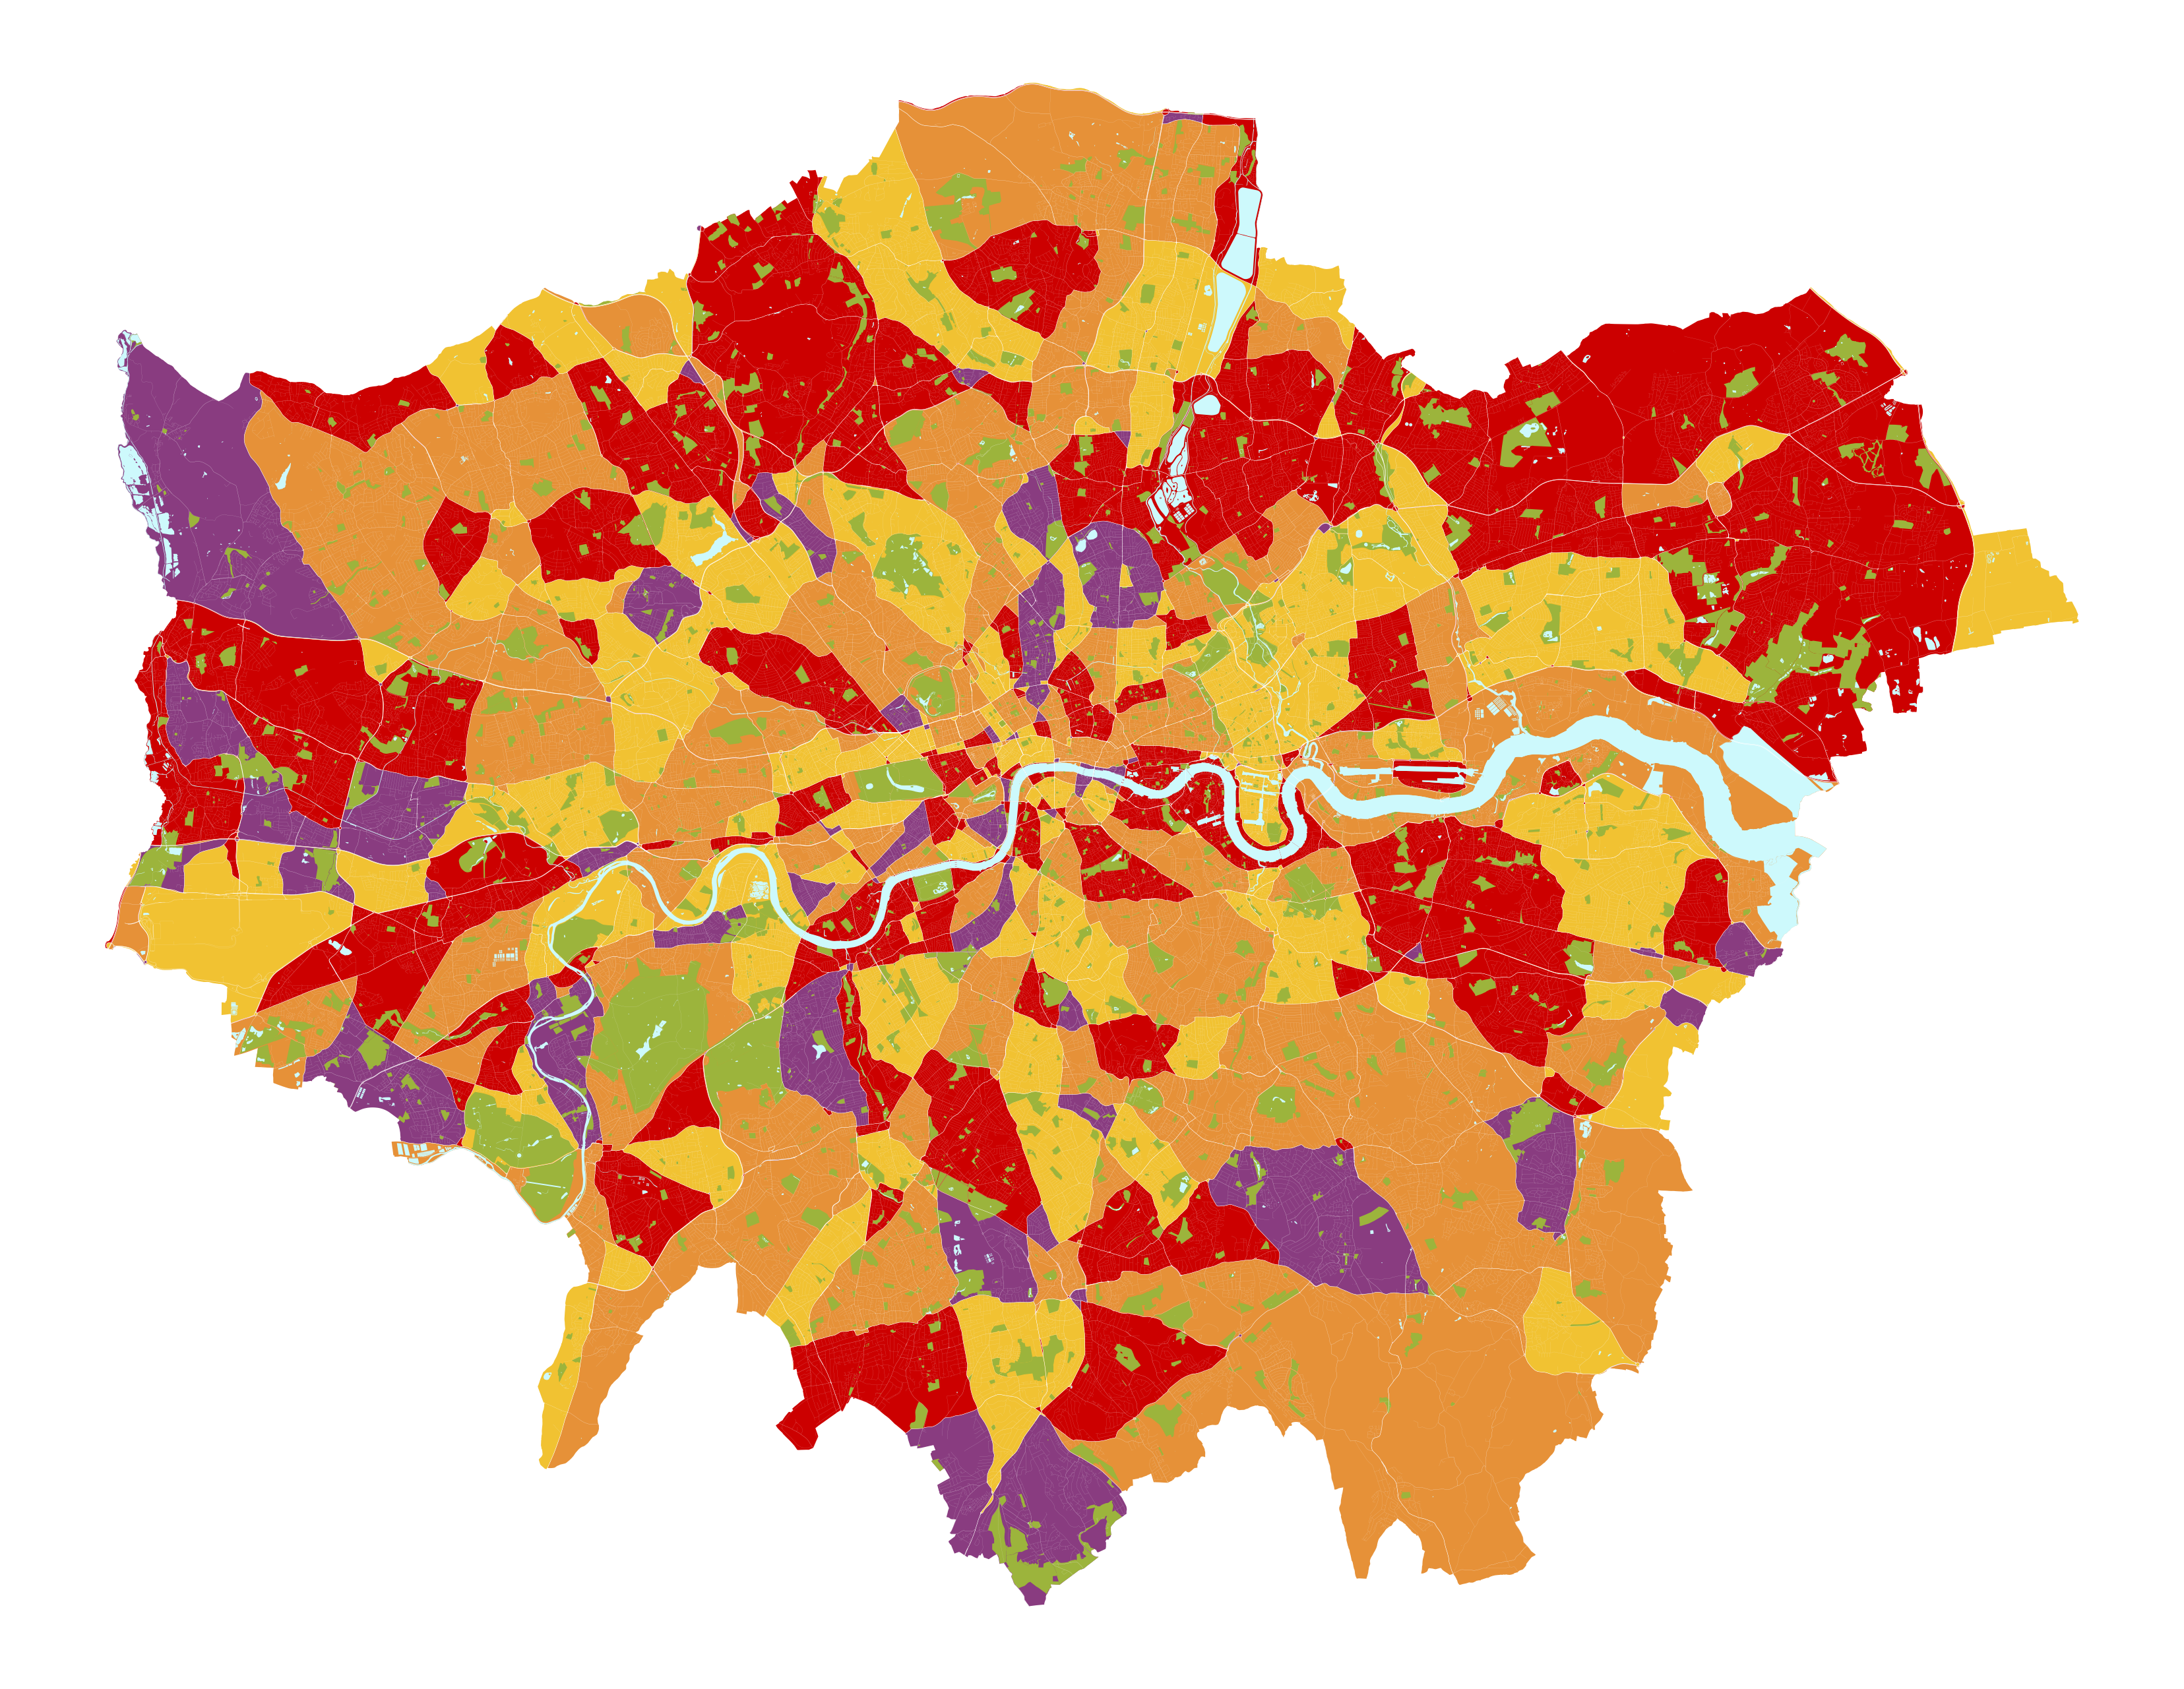

In [26]:
f, ax = plt.subplots(figsize=(46, 33), facecolor="white")
#ax.set_facecolor('white')

polygons.plot(ax=ax, color=polygons.color)

parks.plot(ax=ax, color='#9CB43C')
water.plot(ax=ax, color='#CDF9FC')

buffered_roads.plot(ax=ax, color='white')

plt.axis('off')
plt.show()
f.savefig(f'../data/outputs/test.jpg', dpi=750)